<div align="center">

# **DS201: XÂY DỰNG MẠNG NEURON ĐƠN GIẢN (LAB 01)**

**Họ và tên: Phạm Đình Quang Huy**

**MSSV: 24520689**  
</div>

<b>Hướng dẫn nộp bài:</b>
- Folder chứa toàn bộ source code, đặt tên là <b>\<MSSV\>.zip</b> với \<MSSV\> là MSSV của các bạn.
- Nộp qua course, giảng viên sẽ tạo submission sau mỗi buổi học.

Bộ dữ liệu sử dụng: MNIST dataset.

Link download: http://yann.lecun.com/exdb/mnist/.

In [86]:
import torch.nn as nn
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
import torch.optim as optim
from torchvision import transforms, datasets
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

device = torch.device("cuda" if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [87]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: torch.flatten(x))
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True)
test_dataset = datasets.MNIST(root='./data', train=False, download=True)

X_train = torch.stack([transform(img) for img, _ in train_dataset])
y_train = train_dataset.targets

X_test = torch.stack([transform(img) for img, _ in test_dataset])
y_test = test_dataset.targets

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=64)

print(f"Số lượng mẫu huấn luyện: {len(train_dataset)}")
print(f"Số lượng mẫu kiểm tra: {len(test_dataset)}")

Số lượng mẫu huấn luyện: 60000
Số lượng mẫu kiểm tra: 10000


### Bài 1: Xây dựng mô hình 1-layer MLP và hàm Softmax làm activation function. Huấn luyện mô hình này sử dụng SGD làm optimizer và đánh giá trên các độ đo accuracy, precision, recall và F1-macro. Đánh giá kết quả của mô hình với từng chữ số.

In [88]:
class OneMLP(nn.Module):
    def __init__(self, input_dim=784, output_dim=10, criterion=None, optimizer=torch.optim.SGD, epochs=10):
        super(OneMLP, self).__init__()
        self.full_connect = nn.Linear(input_dim, output_dim)
        self.softmax = nn.Softmax(dim=1)
        self.criterion = criterion if criterion is not None else nn.CrossEntropyLoss()
        self.optimizer = optimizer(self.parameters(), lr=0.01)
        self.epochs = epochs
        self.epoch_error = []
        self.results = []

    def forward(self, x):
        return self.full_connect(x)

    def fit(self, train_loader):
        self.to(device)
        self.train()

        for epoch in range(self.epochs):
            train_loss = 0.0
            for x, y in train_loader:

                self.optimizer.zero_grad()
                x, y = x.to(device), y.to(device)
                y_pred = self(x)
                loss = self.criterion(y_pred, y)
                loss.backward()
                self.optimizer.step()

                train_loss += loss.item() * x.size(0)

            epoch_loss = train_loss / len(train_loader.dataset)
            self.epoch_error.append(epoch_loss)
            print(f"Epoch [{epoch+1}/{self.epochs}] - Loss: {epoch_loss:.4f}")

    def evaluation(self, test_loader):
        self.eval()
        all_preds = []
        all_targets = []

        with torch.no_grad():
            for x, y in test_loader:
                x = x.to(device)
                y_pred_logit = self(x)
                y_pred = torch.argmax(y_pred_logit, dim=1).cpu().numpy()

                all_preds.extend(y_pred)
                all_targets.extend(y.numpy())

        all_preds = np.array(all_preds)
        all_targets = np.array(all_targets)

        acc = accuracy_score(all_targets, all_preds)
        prec = precision_score(all_targets, all_preds, average='macro', zero_division=0)
        rec = recall_score(all_targets, all_preds, average='macro', zero_division=0)
        f1 = f1_score(all_targets, all_preds, average='macro', zero_division=0)
        self.results.append([acc, prec, rec, f1])

        print("\n--- KẾT QUẢ ĐÁNH GIÁ TỔNG THỂ ---")
        print(f"Accuracy:  {acc * 100:.2f}%")
        print(f"Precision (Macro): {prec:.4f}")
        print(f"Recall (Macro):    {rec:.4f}")
        print(f"F1-macro:          {f1:.4f}")

In [89]:
# Call One MLP model, fit on training set and evaluate on test set.
model_1 = OneMLP()
model_1.fit(train_loader)
model_1.evaluation(test_loader)

Epoch [1/10] - Loss: 0.9824
Epoch [2/10] - Loss: 0.5503
Epoch [3/10] - Loss: 0.4709
Epoch [4/10] - Loss: 0.4324
Epoch [5/10] - Loss: 0.4085
Epoch [6/10] - Loss: 0.3917
Epoch [7/10] - Loss: 0.3793
Epoch [8/10] - Loss: 0.3694
Epoch [9/10] - Loss: 0.3613
Epoch [10/10] - Loss: 0.3546

--- KẾT QUẢ ĐÁNH GIÁ TỔNG THỂ ---
Accuracy:  90.86%
Precision (Macro): 0.9078
Recall (Macro):    0.9075
F1-macro:          0.9074


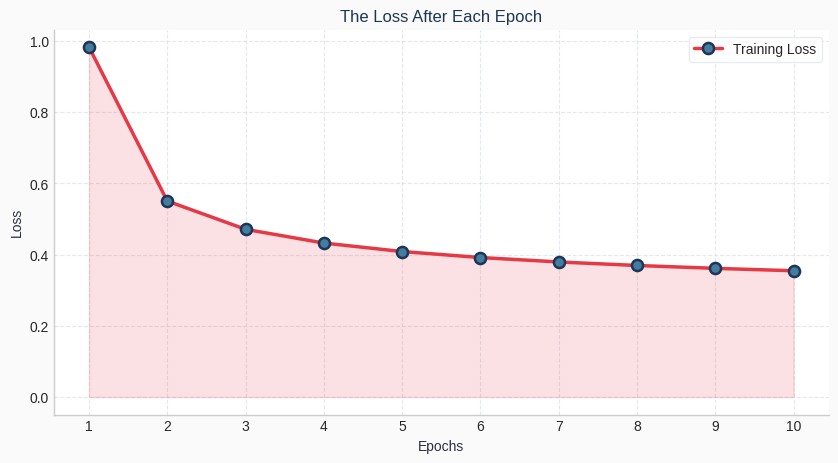

In [90]:
plt.style.use("seaborn-v0_8-whitegrid")
epochs = list(range(1, 11))
loss = model_1.epoch_error

fig, ax = plt.subplots(figsize=(10, 5), facecolor="#fafafa")
ax.set_facecolor("#ffffff")

ax.plot(
    epochs,
    loss,
    color="#e63946",
    linewidth=2.5,
    marker="o",
    markersize=8,
    markerfacecolor="#457b9d",
    markeredgecolor="#1d3557",
    markeredgewidth=1.8,
    label="Training Loss",
)

ax.fill_between(epochs, loss, color="#e63946", alpha=0.15)
ax.set_title("The Loss After Each Epoch",color="#1d3557")
ax.set_xlabel("Epochs", color="#2b2d42")
ax.set_ylabel("Loss", color="#2b2d42")
ax.set_xticks(epochs)
ax.grid(True, linestyle="--", alpha=0.5, color="#cbd5e1")
ax.legend(frameon=True, facecolor="white", edgecolor="#e2e8f0", loc="upper right")

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.show()

### Bài 2: Xây dựng mô hình 3-layer MLP, hàm ReLU và hàm softmax làm activation function. Trong đó activation function cho 2 layer đầu là ReLU và activation function cho layer cuối là Softmax. Huấn luyện mô hình này sử dụng SGD làm optimizer và đánh giá trên các độ đo accuracy, precision, recall và F1-macro. Đánh giá kết quả của mô hình với từng chữ số.


In [91]:
class ThreeLayerMLP(nn.Module):
    def __init__(self, input_dim=784, hidden1=512, hidden2=256, output_dim=10, criterion=None, optimizer=torch.optim.SGD, epochs=10):
        super(ThreeLayerMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden1),
            nn.ReLU(),
            nn.Linear(hidden1, hidden2),
            nn.ReLU(),
            nn.Linear(hidden2, output_dim)
        )
        self.criterion = criterion if criterion is not None else nn.CrossEntropyLoss()
        self.optimizer = optimizer(self.parameters(), lr=0.01)
        self.epochs = epochs
        self.epoch_error = []
        self.results = []

    def forward(self, x):
        return self.network(x)

    def fit(self, train_loader):
        self.to(device)
        self.train()

        for epoch in range(self.epochs):
            train_loss = 0.0
            for x, y in train_loader:

                self.optimizer.zero_grad()
                x, y = x.to(device), y.to(device)
                y_pred = self(x)
                loss = self.criterion(y_pred, y)
                loss.backward()
                self.optimizer.step()

                train_loss += loss.item() * x.size(0)

            epoch_loss = train_loss / len(train_loader.dataset)
            self.epoch_error.append(epoch_loss)
            print(f"Epoch [{epoch+1}/{self.epochs}] - Loss: {epoch_loss:.4f}")

    def evaluation(self, test_loader):
        self.eval()
        all_preds = []
        all_targets = []

        with torch.no_grad():
            for x, y in test_loader:
                x = x.to(device)
                y_pred_logit = self(x)
                y_pred = torch.argmax(y_pred_logit, dim=1).cpu().numpy()

                all_preds.extend(y_pred)
                all_targets.extend(y.numpy())

        all_preds = np.array(all_preds)
        all_targets = np.array(all_targets)

        acc = accuracy_score(all_targets, all_preds)
        prec = precision_score(all_targets, all_preds, average='macro', zero_division=0)
        rec = recall_score(all_targets, all_preds, average='macro', zero_division=0)
        f1 = f1_score(all_targets, all_preds, average='macro', zero_division=0)
        self.results.append([acc, prec, rec, f1])

        print("\n--- KẾT QUẢ ĐÁNH GIÁ TỔNG THỂ ---")
        print(f"Accuracy:  {acc * 100:.2f}%")
        print(f"Precision (Macro): {prec:.4f}")
        print(f"Recall (Macro):    {rec:.4f}")
        print(f"F1-macro:          {f1:.4f}")

In [92]:
# Call ThreeLayerMLP, fit on training set and evaluate on test set.
model_2 = ThreeLayerMLP()
model_2.fit(train_loader)
model_2.evaluation(test_loader)

Epoch [1/10] - Loss: 1.6048
Epoch [2/10] - Loss: 0.5118
Epoch [3/10] - Loss: 0.3755
Epoch [4/10] - Loss: 0.3292
Epoch [5/10] - Loss: 0.3014
Epoch [6/10] - Loss: 0.2794
Epoch [7/10] - Loss: 0.2609
Epoch [8/10] - Loss: 0.2448
Epoch [9/10] - Loss: 0.2296
Epoch [10/10] - Loss: 0.2160

--- KẾT QUẢ ĐÁNH GIÁ TỔNG THỂ ---
Accuracy:  94.07%
Precision (Macro): 0.9405
Recall (Macro):    0.9399
F1-macro:          0.9400


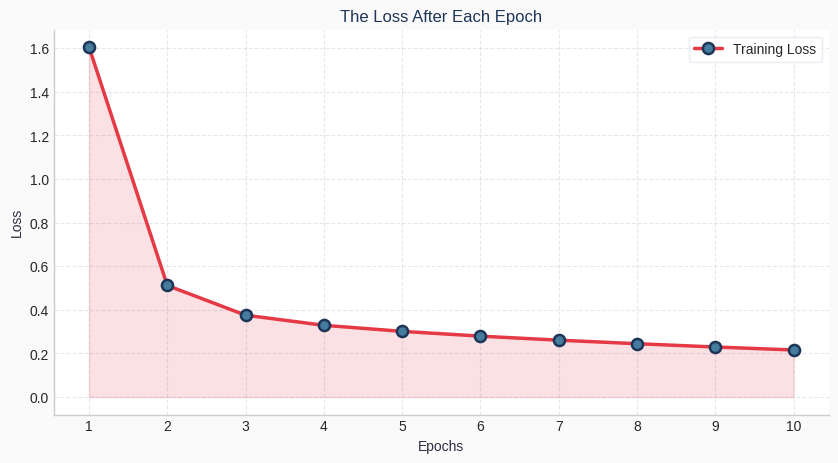

In [93]:
plt.style.use("seaborn-v0_8-whitegrid")
epochs = list(range(1, 11))
loss = model_2.epoch_error

fig, ax = plt.subplots(figsize=(10, 5), facecolor="#fafafa")
ax.set_facecolor("#ffffff")

ax.plot(
    epochs,
    loss,
    color="#e63946",
    linewidth=2.5,
    marker="o",
    markersize=8,
    markerfacecolor="#457b9d",
    markeredgecolor="#1d3557",
    markeredgewidth=1.8,
    label="Training Loss",
)

ax.fill_between(epochs, loss, color="#e63946", alpha=0.15)
ax.set_title("The Loss After Each Epoch",color="#1d3557")
ax.set_xlabel("Epochs", color="#2b2d42")
ax.set_ylabel("Loss", color="#2b2d42")
ax.set_xticks(epochs)
ax.grid(True, linestyle="--", alpha=0.5, color="#cbd5e1")
ax.legend(frameon=True, facecolor="white", edgecolor="#e2e8f0", loc="upper right")

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.show()

## **KẾT QUẢ & NHẬN XÉT:**


In [94]:
one_layer = model_1.results
three_layer = model_2.results

one_layer_df = pd.DataFrame(one_layer, columns=['Accuracy', 'Precision', 'Recall', 'F1-macro'])
three_layer_df = pd.DataFrame(three_layer, columns=['Accuracy', 'Precision', 'Recall', 'F1-macro'])

final_results = pd.concat([one_layer_df, three_layer_df], axis=0, keys=['One Layer MLP', 'Three Layer MLP']).droplevel(1).T
final_results

,One Layer MLP,Three Layer MLP
Accuracy,0.908600,0.940700
Precision,0.907759,0.940454
Recall,0.907450,0.939893
F1-macro,0.907362,0.939985


→ Cả hai hệ thống đều cho kết quả rất khả quan trên tập dữ liệu MNIST. Tuy nhiên, tất cả các chỉ số của hệ thống ba lớp full connect MLP đều cao hơn khoảng **≈0.04** điểm. Cụ thể: accuracy, precision, recall và f1-macro của một lớp là 0.91 còn của ba lớp là 0.94

**TỔNG KẾT:**
Bài lab đầu tiên học cách xây dựng một mạng MLP cơ bản để phân loại chữ viết trong tập MNIST đã mang lại kiến thức cơ bản về quy trình xây dựng một mạng neural network cho sinh viên, ngoài ra còn giúp sinh viên tránh các lỗi cơ bản nhất khi thực hiện xây dựng một mạng nhân tạo.